# 5. PCA

In [1]:
# Imports necessary libraries.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec 
import seaborn as sns
import hashlib
from sklearn.datasets import fetch_openml

# Generate seed based on my college ID.
username = "sudhanva.joshi"
seed = int(hashlib.sha256(username.encode()).hexdigest(), 16) % (2**32)
print("Seed generated:", seed)
rng = np.random.default_rng(seed)

# Set plotting theme and helper functons.
sns.set_theme(context="paper", style="darkgrid",
              palette="rocket", font="Nimbus Roman")

def plotinfo(title, x, y, userid=username):
    plt.text(0.95, -0.1, userid, ha="right", va="top",
             transform=plt.gca().transAxes, fontsize=10,
             color="gray", alpha=0.7)
    plt.title(title, fontsize=14, fontweight='bold')
    plt.xlabel(x, fontsize=12)
    plt.ylabel(y, fontsize=12)
    plt.tight_layout()
    plt.show()

def coordplot(ax, title, x_label, y_label):
    ax.set_title(title)
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)


# Loaded and Preprocessed the Data.

Seed generated: 1027714457


### 5.1 Custom Implementation

In [2]:
class PCA:
    """
    A custom implementation of Principal Component Analysis (PCA) from scratch.
    """
    def __init__(self, n_components):
        """
        Initializes the PCA model.
        
        Args:
            n_components (int): The number of principal components to keep.
        """
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        """
        Fits the PCA model to the data X to obtain the principal components.

        Args:
            X (np.ndarray): The training data of shape (n_samples, n_features).
        """
        # 1. Center the data by subtracting the mean
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # 2. Compute the covariance matrix
        # 'rowvar=False' as features are in columns
        cov_matrix = np.cov(X_centered, rowvar=False)

        # 3. Calculate eigenvalues and eigenvectors of the covariance matrix
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

        # 4. Sort eigenvectors by descending eigenvalues
        sorted_indices = np.argsort(eigenvalues)[::-1]
        sorted_eigenvalues = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]

        # 5. Store the principal components (top n_components eigenvectors)
        self.components_ = sorted_eigenvectors[:, :self.n_components]

        # 6. Calculate the explained variance ratio for each component
        total_variance = np.sum(sorted_eigenvalues)
        self.explained_variance_ratio_ = sorted_eigenvalues / total_variance
        
    def transform(self, X):
        """
        Transforms the data by projecting it onto the principal components.

        Args:
            X (np.ndarray): The data to transform, shape (n_samples, n_features).

        Returns:
            np.ndarray: The transformed data of shape (n_samples, n_components).
        """
        if self.components_ is None:
            raise RuntimeError("PCA instance has not been fitted. Call fit() first.")
        
        X_centered = X - self.mean_
        X_transformed = np.dot(X_centered, self.components_)
        return X_transformed

    def inverse_transform(self, X_transformed):
        """
        Transforms data back to its original space from the reduced space.

        Args:
            X_transformed (np.ndarray): The transformed data, shape (n_samples, n_components).

        Returns:
            np.ndarray: The reconstructed data in the original feature space.
        """
        if self.components_ is None:
            raise RuntimeError("PCA instance has not been fitted. Call fit() first.")
        
        X_reconstructed_centered = np.dot(X_transformed, self.components_.T)
        X_reconstructed = X_reconstructed_centered + self.mean_
        return X_reconstructed

    def checkPCA(self, X):
        """
        Checks if the class correctly reduces the dimensions of the data.

        Args:
            X (np.ndarray): The data to test on, shape (n_samples, n_features).

        Returns:
            bool: True if the transformed data has the correct dimensions, False otherwise.
        """
        try:
            self.fit(X)
            X_transformed = self.transform(X)
            if X_transformed.shape == (X.shape[0], self.n_components):
                print("checkPCA Passed: Transformed data has the correct shape.")
                return True
            else:
                print(f"checkPCA Failed: Expected shape {(X.shape[0], self.n_components)}, but got {X_transformed.shape}.")
                return False
        except Exception as e:
            print(f"checkPCA Failed with an error: {e}")
            return False

## 5.2 PCA on MNIST

It is observed that the number of principled components are related directly to the clarity of the image pixels. As the dimensionality of the image increases, more information on each pixel's intensity is obtained, which leads to 'sharper' and clearer images to view.

--- Applying PCA on MNIST ---


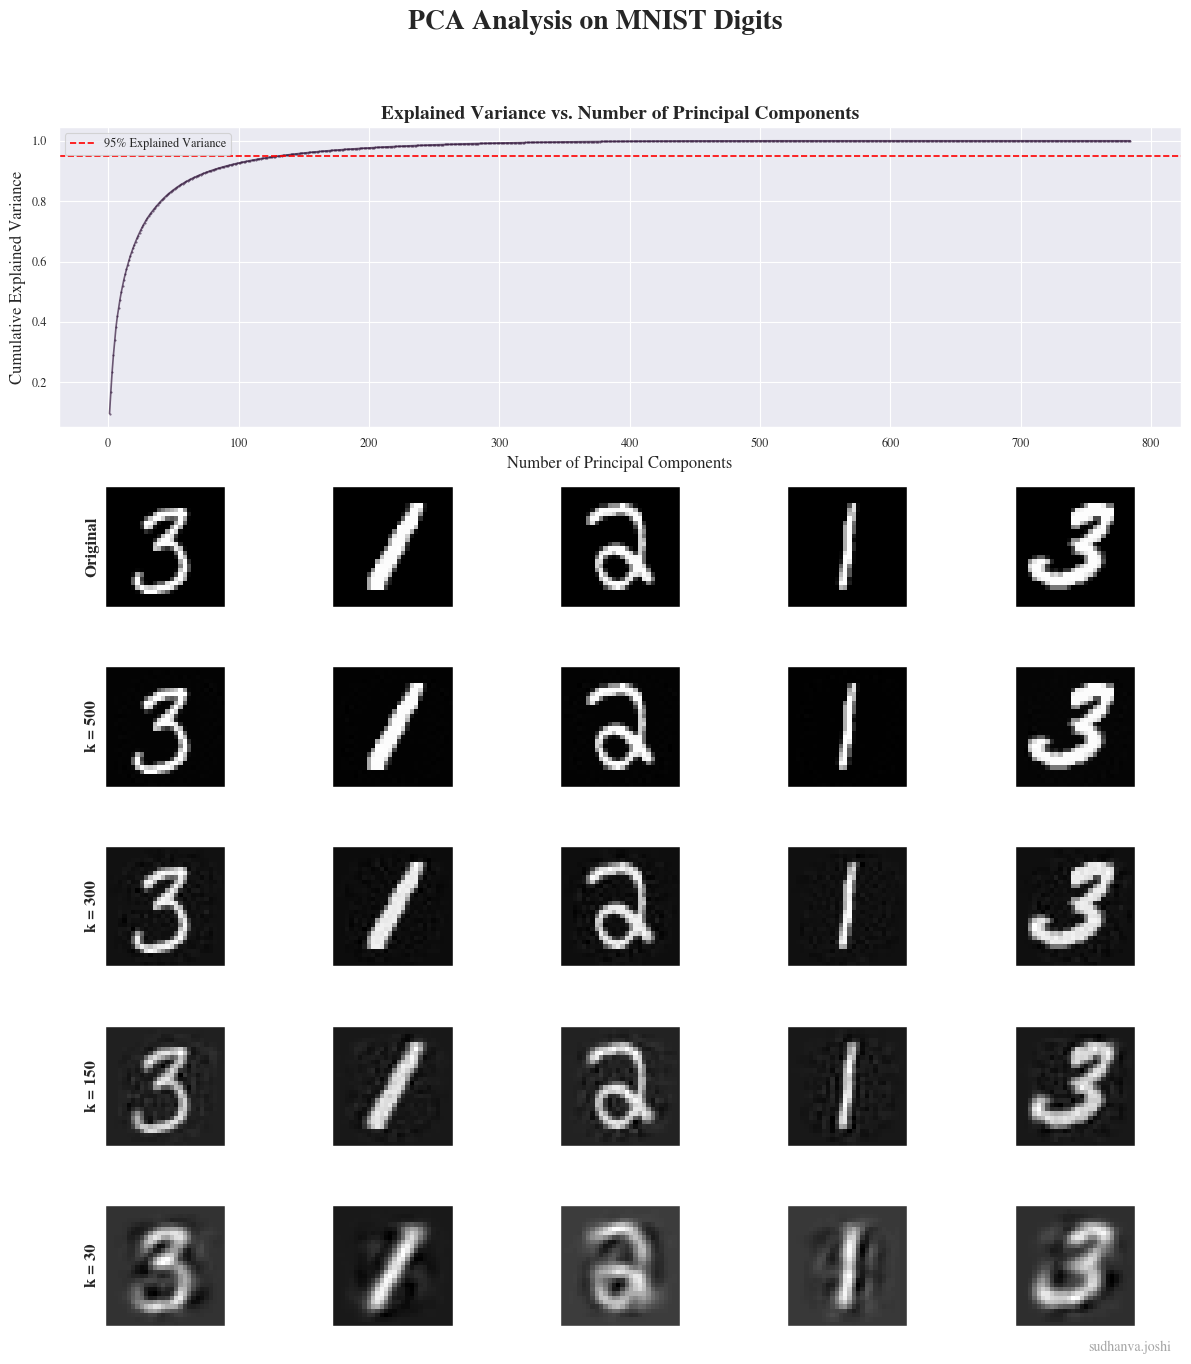

In [3]:
# --- Applying PCA on MNIST (from your script) ---
print("--- Applying PCA on MNIST ---")
mnist = fetch_openml('mnist_784', version=1, as_frame=False, parser='liac-arff')
X, y = mnist["data"], mnist["target"]
y = y.astype(np.uint8)

X_subset, y_subset = [], []
for i in range(10):
    indices = np.where(y == i)[0]
    random_indices = rng.choice(indices, 100, replace=False)
    X_subset.append(X[random_indices])
    y_subset.append(y[random_indices])

X_subset = np.concatenate(X_subset, axis=0)
y_subset = np.concatenate(y_subset, axis=0)
X_subset_scaled = X_subset / 255.0

# Calculate explained variance
n_features = X_subset_scaled.shape[1]
pca_full = PCA(n_components=n_features) 
pca_full.fit(X_subset_scaled)
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

# Select 5 random images to visualize
num_images_to_show = 5
image_indices = rng.choice(len(X_subset_scaled), num_images_to_show, replace=False)
original_images = X_subset_scaled[image_indices]
target_dims = [500, 300, 150, 30]


fig = plt.figure(figsize=(12, 14))
gs = gridspec.GridSpec(3 + len(target_dims), num_images_to_show, figure=fig)

ax_variance = fig.add_subplot(gs[0:2, :])
ax_variance.plot(range(1, n_features + 1), cumulative_variance, marker='.', linestyle='-', markersize=1, alpha=0.7)
ax_variance.axhline(y=0.95, color='r', linestyle='--', label='95% Explained Variance')
ax_variance.set_title("Explained Variance vs. Number of Principal Components", fontsize=14, fontweight='bold')
ax_variance.set_xlabel("Number of Principal Components", fontsize=12)
ax_variance.set_ylabel("Cumulative Explained Variance", fontsize=12)
ax_variance.legend()
ax_variance.grid(True)


for i, img in enumerate(original_images):
    ax = fig.add_subplot(gs[2, i])
    ax.imshow(img.reshape(28, 28), cmap='gray')
    if i == 0:
        ax.set_ylabel("Original", fontweight='bold', fontsize=12)
    ax.set_xticks([])
    ax.set_yticks([])

for row_offset, dim in enumerate(target_dims):
    grid_row = 3 + row_offset
    
    pca = PCA(n_components=dim)
    pca.fit(X_subset_scaled)
    transformed_images = pca.transform(original_images)
    reconstructed_images = pca.inverse_transform(transformed_images)
    
    for i, img in enumerate(reconstructed_images):
        ax = fig.add_subplot(gs[grid_row, i])
        ax.imshow(img.reshape(28, 28), cmap='gray')
        if i == 0:
            ax.set_ylabel(f"k = {dim}", fontweight='bold', fontsize=12)
        ax.set_xticks([])
        ax.set_yticks([])

fig.suptitle("PCA Analysis on MNIST Digits", fontsize=20, fontweight='bold')
fig.text(0.98, 0.02, username, ha="right", va="bottom", fontsize=10, color="gray", alpha=0.7)
fig.tight_layout(rect=[0, 0.03, 1, 0.95]) 
plt.show()